In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from plotnine import *
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from metabolomic_utils import *

#### Prepare data

In [2]:
## General
project_dir = 'C:/Users/alisa/phd/FAP/'
mdata = pd.read_csv(project_dir + 'metadata/clean/metadata_combined.csv')
palette = pd.read_csv(project_dir + 'metadata/clean/project_palette.csv')
color_mapping = dict(zip(palette['label'], palette['color']))

## Metabolomics
metabolomics_norm = pd.read_csv(project_dir + 'metabolomics/transformed_df.csv').rename(columns={'Unnamed: 0': 'case_number'})
compound_names = pd.read_csv(project_dir + 'metabolomics/compound_names.csv').drop(columns=['Unnamed: 0'])
compund_dict = {compound_names["compound_id"][i]: compound_names["compound_name"][i] for i in range(len(compound_names))}
## Taxonomy
taxa = pd.read_csv(project_dir + 'processed_data/genus_ra_non_rare.csv')

In [3]:
metabolites = metabolomics_norm.columns.drop('case_number').tolist() 
genera = taxa.columns.drop('sample_id').tolist()  # check that all columns are present in taxa
mdata_cols = mdata.columns.tolist()  # check that all columns are present in mdata

#### Prepare the data

In [113]:
# Ensure both columns have the same data type before merging
metabolomics_norm['case_number'] = metabolomics_norm['case_number'].astype(str)
mdata['case_number'] = mdata['sample_id'].astype(str)
phenotype_order = [ "Classical FAP", "Non-classical FAP", "Control"]
df = pd.merge(metabolomics_norm, mdata, on = "case_number", how='left')
df = df[df.phenotype.isin(phenotype_order)]

df["cohort"] = np.where(df["cohort"].isna(), "FAP Cohort", df["cohort"])
df["indication"] = np.where(df["cohort"] == "FAP Cohort", "FAP", df["phenotype"])
df["is_fap"] = np.where(df["cohort"] == "FAP Cohort", 1, 0)
df["is_male"] = df["gender"] == "Male"

# Force numeric on relevant columns
for col in df.columns:
    try:
        df[col] = pd.to_numeric(df[col])
    except ValueError:
        df[col] = df[col].astype(str)
        
df['phenotype'] = pd.Categorical(df['phenotype'], categories=phenotype_order, ordered=True)

#### Cluster correlated features

In [5]:
import networkx as nx

correlation_matrix = df[metabolites].corr()
threshold = 0.8
high_corr = (correlation_matrix.abs() >= threshold).astype(int)

graph = nx.Graph()
for i, metabolite in enumerate(correlation_matrix.columns):
    for j, other_metabolite in enumerate(correlation_matrix.columns):
        if i < j and high_corr.iloc[i, j]:  # Add edges for high correlations
            graph.add_edge(metabolite, other_metabolite)
            
clusters = list(nx.connected_components(graph))
# Step 5: Summarize cluster values
for cluster_id, cluster in enumerate(clusters):
    cluster_metabolites = list(cluster)
    df[f'cluster_{cluster_id}_mean'] = df[cluster_metabolites].mean(axis=1)
    
metabolite_to_cluster = {metabolite: cluster_id for cluster_id, cluster in enumerate(clusters) for metabolite in cluster}

C:\Users\alisa\AppData\Local\Temp\ipykernel_5964\78700967.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
C:\Users\alisa\AppData\Local\Temp\ipykernel_5964\78700967.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
C:\Users\alisa\AppData\Local\Temp\ipykernel_5964\78700967.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use 

c:\Users\alisa\anaconda3\envs\alisa\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
c:\Users\alisa\anaconda3\envs\alisa\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.


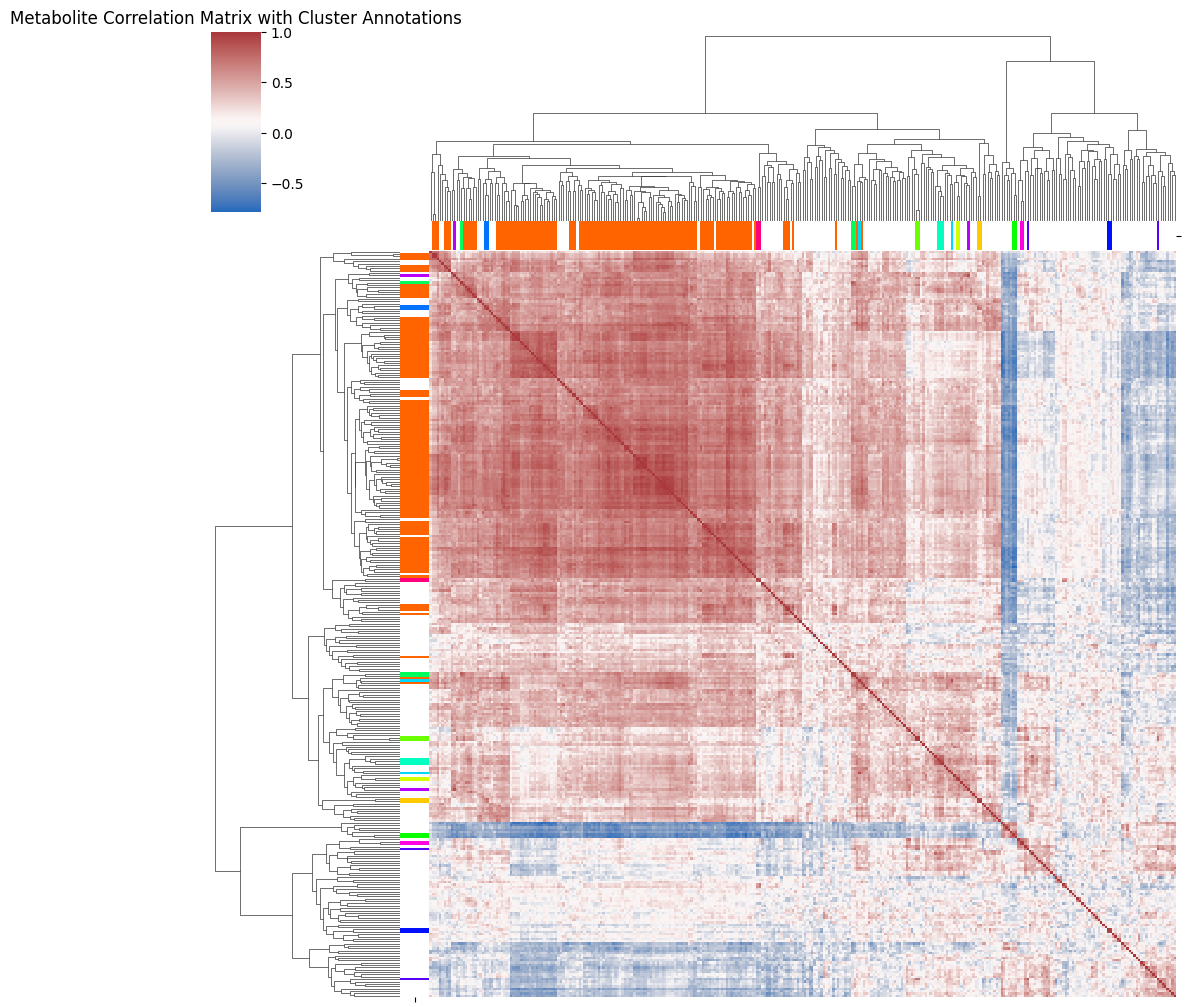

In [6]:
metabolites_order = correlation_matrix.columns
unique_clusters = sorted(set(metabolite_to_cluster.values()))
palette = sns.color_palette("hsv", len(unique_clusters))

cluster_to_color = {cluster_id: palette[i] for i, cluster_id in enumerate(unique_clusters)}
cluster_colors = pd.Series([metabolite_to_cluster.get(m, -1) for m in metabolites_order], index=metabolites_order)
col_colors = cluster_colors.map(cluster_to_color)

sns.clustermap(
    correlation_matrix,  xticklabels=False, yticklabels=False,
    row_colors=col_colors,
    col_colors=col_colors,
    cmap='vlag',
    figsize=(10, 10)
)
plt.title("Metabolite Correlation Matrix with Cluster Annotations")
plt.show()

In [7]:
clustered_metabolites = list(metabolite_to_cluster.keys())
metabolite_to_cluster_df = pd.DataFrame(list(metabolite_to_cluster.items()), columns=['metabolite', 'cluster'])
unclusted_metabolites = [metabolite for metabolite in metabolites if metabolite not in clustered_metabolites]
print(f"{len(clustered_metabolites)} metabolites clustered into {len(clusters)} clusters")
print(f"{len(unclusted_metabolites)} metabolites not clustered")
clustered_features = [f'cluster_{x}_mean' for x in range(len(clusters))]

148 metabolites clustered into 14 clusters
167 metabolites not clustered


,case_number,X01338,X07743,X01951,X01913,X10955,X00159,X00831,X02962,X00686,...,cluster_4_mean,cluster_5_mean,cluster_6_mean,cluster_7_mean,cluster_8_mean,cluster_9_mean,cluster_10_mean,cluster_11_mean,cluster_12_mean,cluster_13_mean
0,36161549,0.679388,-0.514996,-1.557902,-1.231930,-1.391852,-1.848093,-0.216016,1.079870,0.003376,...,1.325327,-0.706165,0.058130,-1.073166,-1.887785,0.421961,1.061386,-2.030137,-1.381550,-1.278473
1,35727911,0.809114,0.737061,-2.041861,0.406183,-1.822589,-0.710004,-1.510934,2.944592,2.458696,...,1.422956,-1.104624,-0.163099,-1.056436,-0.252036,0.597817,0.504720,-1.789854,0.498423,-1.279520
2,35956773,0.942105,0.770455,-0.952308,-0.905274,-0.275191,0.527055,-0.826098,-0.421264,-0.676086,...,1.953787,0.260045,-0.116554,0.074724,-0.692829,0.342656,1.093408,0.794305,0.206697,-0.445944
3,36532014,-0.711044,-1.064064,-2.578498,-1.151875,-1.762388,-1.506817,-2.017364,-2.337210,-0.199791,...,1.155476,-1.630609,-2.135145,-1.119382,-2.964748,-1.017265,0.529536,-1.581491,-1.139511,-1.128947
4,36531969,-1.081183,0.258473,-0.356081,0.927301,-0.952844,0.825751,-1.132292,1.124467,1.027511,...,0.271842,0.510026,0.720369,0.466562,0.639850,-0.252354,1.269570,-1.209861,-0.424167,-0.266342
5,36058959,0.273418,-1.178598,-2.561412,-1.399854,-1.770080,-1.606372,-1.012454,-1.302149,0.768456,...,1.114416,-2.187438,-1.810094,-1.620562,-2.380005,-0.881626,-0.130434,-2.282743,-1.597001,-1.110712
6,36224673,-0.880637,0.688235,-2.646120,-0.820977,-1.829443,-1.706469,-0.798080,-0.508582,-1.610243,...,1.419842,-0.054573,-1.907215,-1.132877,-1.577659,-0.969043,1.777353,-1.225247,-0.092608,-1.146485
7,35919869,0.745095,1.076827,0.525207,-1.490801,-0.719474,-1.016356,-0.915994,-1.238388,-0.369338,...,-0.104584,-0.524299,0.124886,0.696867,-1.561236,0.587109,0.736847,1.777806,0.284691,1.151046
8,35919746,0.288170,-1.143828,-1.004190,-1.371052,0.097852,-1.906005,-1.664484,0.604934,-1.892318,...,1.668081,-3.188071,0.481203,-0.521781,-0.635890,1.774712,-1.353482,-1.314250,-1.712898,-1.286387
9,36161463,1.161228,0.382351,-0.103629,2.010045,0.522900,1.069563,-1.297672,-0.007855,-0.700425,...,0.519615,0.869616,-0.138374,-1.099473,0.180313,2.475948,0.358392,-1.125894,0.183945,-0.776110


In [9]:
metabolite_to_cluster_df.to_csv(project_dir + 'metabolomics/metabolite_to_cluster.csv', index=False)
df.to_csv(project_dir + 'metabolomics/metabolomics_w_clustered_features.csv', index=False)

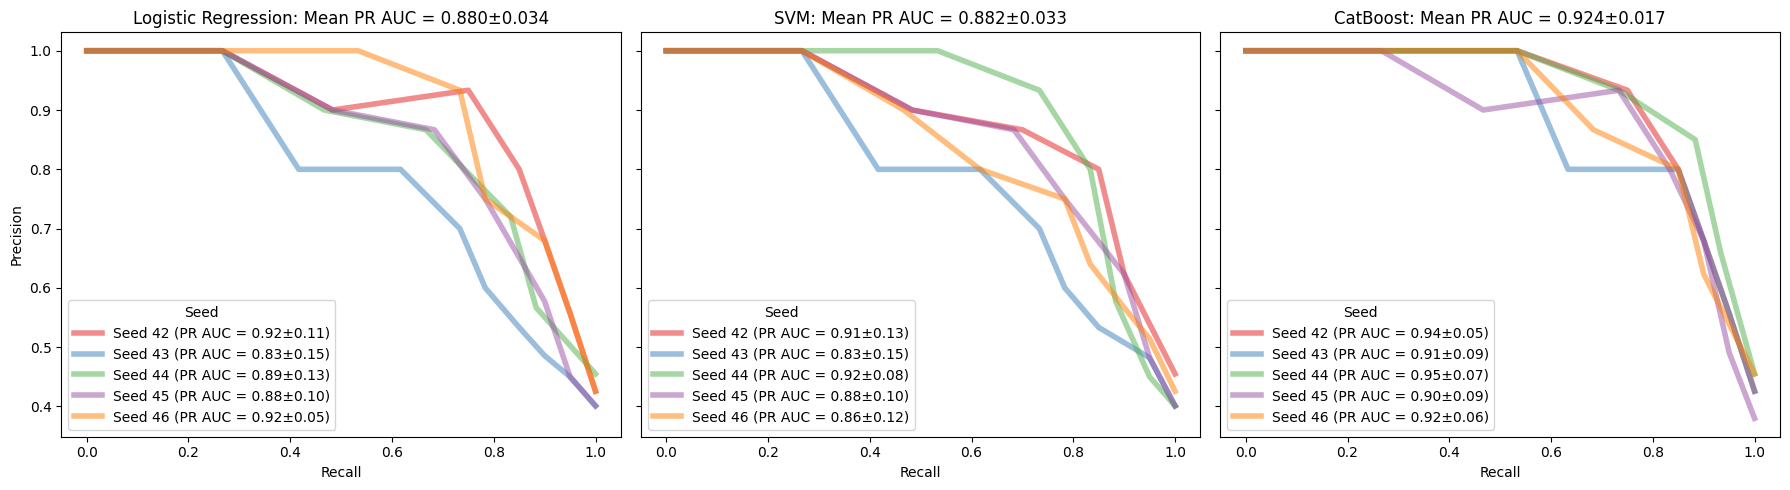

In [145]:
X = df[clustered_features + unclusted_metabolites].dropna(axis=1)
y = df.dropna(axis=1)["is_fap"]
pr_df, feat_imp = evaluate_models_n_times(X, y, n_splits=5, n_times=5)
plot_avg_pr_curves(pr_df)

In [137]:
pr_df[pr_df["model"] == "SVM"]['pr_auc'].unique().mean()

0.8821904761904762

In [141]:
pr_df[pr_df["model"] == "CatBoost"][["balanced_acc", "balanced_acc_std"]].drop_duplicates().mean()

balanced_acc        0.866429
balanced_acc_std    0.082961
dtype: float64

In [67]:
top_features = feat_imp[(feat_imp.model == "CatBoost")]
target_features = top_features['feature'].value_counts().to_frame().query("count == 5").index.to_list()
top_features = top_features[top_features['feature'].isin(target_features)]
top_features

,feature,model,importance_mean,importance_std,seed
21,cluster_11_mean,CatBoost,1.948384,1.672167,Seed 42
22,X02962,CatBoost,0.261110,0.145111,Seed 42
23,SL00144,CatBoost,0.424364,0.211358,Seed 42
26,X00008,CatBoost,0.694716,0.600004,Seed 42
27,X00232,CatBoost,0.974882,0.966004,Seed 42
...,...,...,...,...,...
345,SL00059,CatBoost,0.498126,0.270972,Seed 46
347,SL00263,CatBoost,0.186391,0.110942,Seed 46
350,SL00349,CatBoost,9.411486,4.232022,Seed 46
352,SL00368,CatBoost,1.183224,1.180983,Seed 46


In [68]:
top_features = feat_imp[(feat_imp.model == "CatBoost")]
target_features = top_features['feature'].value_counts().to_frame().query("count == 5").index.to_list()
top_features = top_features[top_features['feature'].isin(target_features)]
top_features = top_features.groupby('feature').agg({'importance_mean': 'mean'}).reset_index().sort_values(by='importance_mean', ascending=False)
top_features = top_features.merge(compound_names, left_on="feature", right_on="compound_id", how="left")
top_features

,feature,importance_mean,compound_id,compound_name,compound_class
0,H00326,13.721088,H00326,Thiamine,Vitamin
1,SL00349,10.921026,SL00349,Oridonin,NaN
2,X00789,6.921739,X00789,Urolithin A,NaN
3,cluster_11_mean,1.755224,NaN,NaN,NaN
4,X00232,1.205752,X00232,Cholic acid,"Bile acids, alcohols and derivatives"
5,SL00368,1.160126,SL00368,Paederoside,NaN
6,X00008,0.500030,X00008,Carnitine,Acyl carnitines
7,X00156,0.486002,X00156,Piperine,Alkaloids and derivatives
8,X09054,0.471212,X09054,Agmatine,Guanidines
9,X03781,0.434075,X03781,"7,8-Dihydroxyflavone",Flavones


In [48]:
def plot_boxplot_with_scatter(df, x_col, y_col, color_col, title):
    plot = (
        ggplot(df, aes(x=x_col, y=y_col, color = color_col, fill = color_col)) +
        geom_boxplot(outlier_shape="", alpha=0.3) +  # Align boxes
        geom_jitter(size=2, alpha=0.8, position=position_jitterdodge(jitter_width=0.5)) +
        scale_fill_manual(values=color_mapping) +
        scale_color_manual(values=color_mapping) +
        theme_bw() +
        theme(figure_size=(6, 6), legend_position="none") +
        labs(title=title, x=x_col, y=y_col, fill=color_col, color=color_col)
    )
    return plot

In [ ]:
for feature in top_features["feature"]:
    ggp = (plot_boxplot_with_scatter(df, "phenotype", feature, "phenotype",  title = compund_dict[feature]) + 
           labs(y = "Peak Area")) + theme(figure_size=(4,4), legend_position="none")
    display(ggp)

In [ ]:
group1 = df[df["phenotype"] == "Classical FAP"]
group2 = df[df["phenotype"] == "Non-classical FAP"]

# Perform Mann-Whitney U test on each numeric column
p_values = []
features = []
effect_sizes = []

for col in metabolites:
    try:
        u_stat, p = mannwhitneyu(group1[col], group2[col], alternative='two-sided')
        n1, n2 = len(group1[col]), len(group2[col])
        r = 1 - (2 * u_stat) / (n1 * n2)  # Rank-biserial correlation
        
        p_values.append(p)
        effect_sizes.append(r)
        features.append(col)
    except Exception as e:
        print(f"Skipping {col} due to error: {e}")

# Ensure 1D array
p_values = np.array(p_values).flatten()
reject, fdr_corrected_pvals, _, _ = multipletests(p_values, alpha=0.1, method='fdr_bh')

# Result DataFrame
results = pd.DataFrame({
    'feature': features,
    'p_value': p_values,
    'fdr': fdr_corrected_pvals,
    'significant': reject,
    'effect_size_r': effect_sizes
})

In [98]:
#results = results.merge(compound_names, left_on="feature", right_on="compound_id", how="left")
results["-log10(FDR)"] = -np.log10(results["fdr"])
results = results.merge(compound_names, left_on="feature", right_on="compound_id", how="left")
results['label'] = results['compound_name'].where(results['significant'], "")
results['color'] = results['effect_size_r'].apply(lambda x: 'Non-classical FAP' if x > 0 else 'Classical FAP')
results.loc[results['significant'] == False, 'color'] = 'grey'

# Filter for FDR < 0.1
significant_results = results[results['fdr'] < 0.1].sort_values('p_value')

In [99]:
significant_results[significant_results['color'] == 'Classical FAP']

,feature,p_value,fdr,significant,effect_size_r,-log10(FDR),compound_id,compound_name,compound_class,label,color
290,SL00378,0.001786,0.008398,True,-0.833333,2.075849,SL00378,Taurocholic acid,"Bile acids, alcohols and derivatives",Taurocholic acid,Classical FAP
42,H00055,0.003731,0.014510,True,-0.785714,1.838344,H00055,Creatine,"Amino acids, peptides, and analogues",Creatine,Classical FAP
276,SL00167,0.007184,0.022859,True,-0.738095,1.640943,SL00167,Phosphocholine,Quaternary ammonium salts,Phosphocholine,Classical FAP
61,SL00374,0.009764,0.027219,True,-0.714286,1.565130,SL00374,Glycocholic acid,"Bile acids, alcohols and derivatives",Glycocholic acid,Classical FAP
43,X00028,0.009764,0.027219,True,-0.714286,1.565130,X00028,Creatinine,"Amino acids, peptides, and analogues",Creatinine,Classical FAP
37,X00232,0.022108,0.048700,True,-0.642857,1.312467,X00232,Cholic acid,"Bile acids, alcohols and derivatives",Cholic acid,Classical FAP
134,SL00376,0.022108,0.048700,True,-0.642857,1.312467,SL00376,Taurodeoxycholic acid,"Bile acids, alcohols and derivatives",Taurodeoxycholic acid,Classical FAP


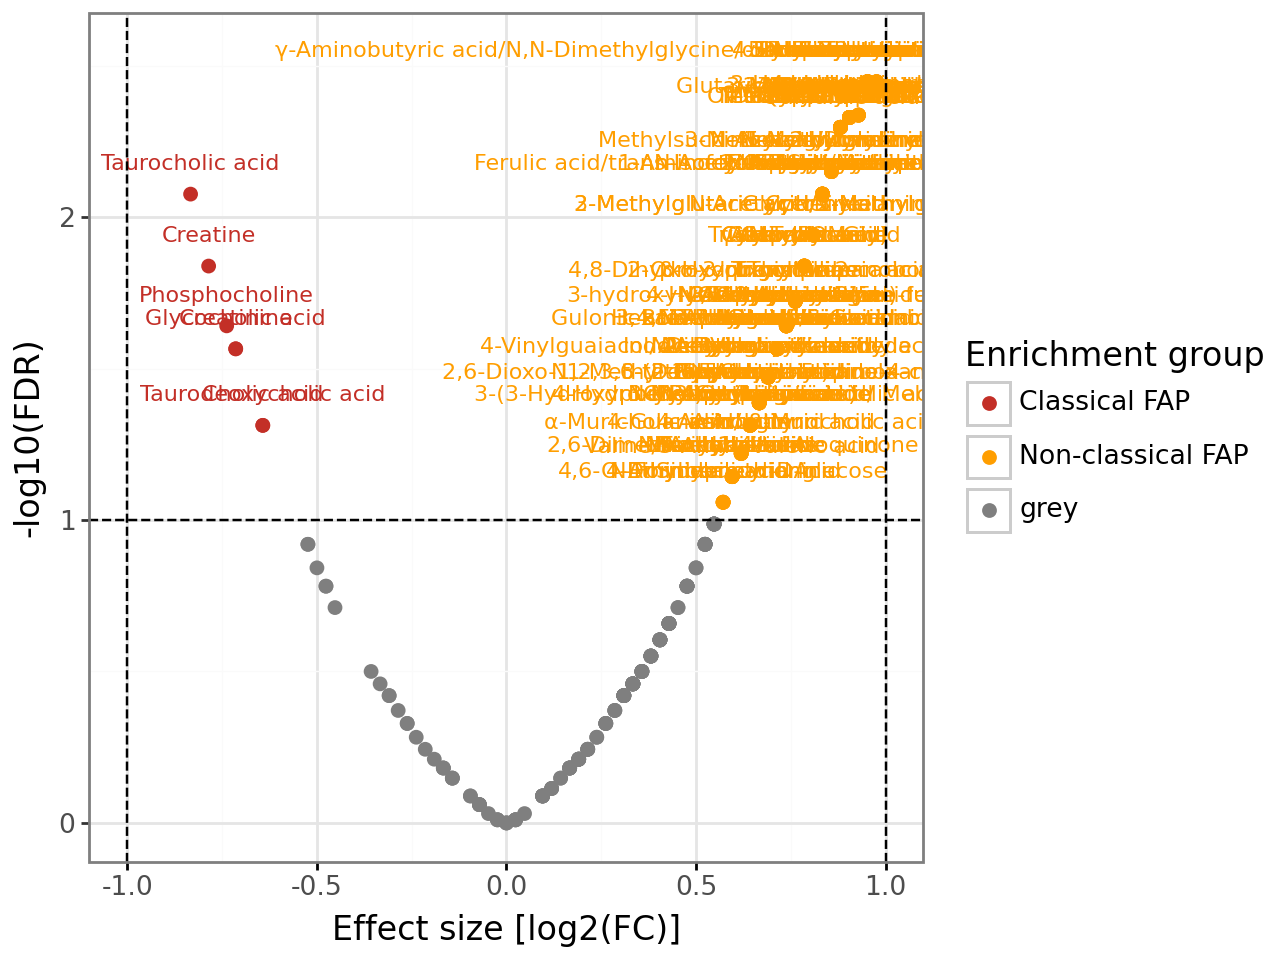

In [88]:
plot_volcano(results, "effect_size_r", "-log10(FDR)", "color", "label") + scale_color_manual(values=color_mapping)

In [82]:
def plot_volcano(df,
                 x_var="coef",
                 y_var="-log10(FDR)",
                 color_var="color",
                 label_var="label",
                 fdr_min=0.1,
                 coef_min=1):

    p = (
        ggplot(df, aes(x=x_var, y=y_var, color=color_var))
        + geom_point(size=2)
        + geom_text(aes(label=label_var), size=8, nudge_y=0.1, show_legend=False)
        + labs(x="Effect size [log2(FC)]", y="-log10(FDR)")
        + guides(color=guide_legend(
            title="Enrichment group",
            override_aes={"label": ""}
        ))
        + geom_hline(yintercept=-np.log10(fdr_min), linetype="dashed", color="black")
        + geom_vline(xintercept=coef_min, linetype="dashed", color="black")
        + geom_vline(xintercept=-coef_min, linetype="dashed", color="black")
        + theme_bw(base_size=12)
    )

    return p

Mann-Whitney U test p-value: 0.08713871508586012 Effect size r: 0.48809523809523814


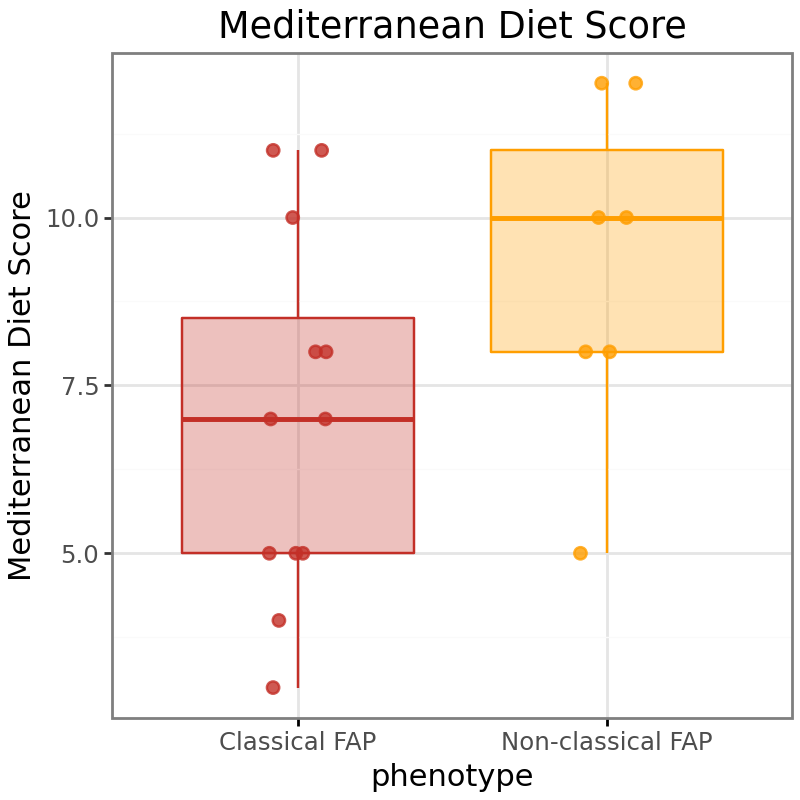

In [120]:
ggdata = df[df.cohort == "FAP Cohort"][['patient_id', 'phenotype','med_diet_sum']].drop_duplicates()
group1 = ggdata[ggdata["phenotype"] == "Classical FAP"]
group2 = ggdata[ggdata["phenotype"] == "Non-classical FAP"]

u_stat, p = mannwhitneyu(group1["med_diet_sum"], group2["med_diet_sum"], alternative='two-sided')
n1, n2 = len(group1["med_diet_sum"]), len(group2["med_diet_sum"])
r = 1 - (2 * u_stat) / (n1 * n2)  # Rank-biserial correlation
print("Mann-Whitney U test p-value:", p, "Effect size r:", r)
plot_boxplot_with_scatter(ggdata, "phenotype", "med_diet_sum", "phenotype",  title = "Mediterranean Diet Score") + labs(y = "Mediterranean Diet Score") + theme(figure_size=(4,4), legend_position="none")

In [133]:
df[~df["is_surgery"] & df["is_fap"] == 1]

,case_number,X01338,X07743,X01951,X01913,X10955,X00159,X00831,X02962,X00686,...,cohort,group.name,is_colono,is_polip,is_polip_history,batch,is_surgery,indication,is_fap,is_male
2,35956773,0.942105,0.770455,-0.952308,-0.905274,-0.275191,0.527055,-0.826098,-0.421264,-0.676086,...,FAP Cohort,FAP,False,True,False,Batch 24,False,FAP,1,True
4,36531969,-1.081183,0.258473,-0.356081,0.927301,-0.952844,0.825751,-1.132292,1.124467,1.027511,...,FAP Cohort,FAP,False,True,False,Batch 24,False,FAP,1,True
16,36387133,-0.252875,1.118253,0.026892,-1.529599,-1.252310,0.520562,-1.019368,-1.030843,-0.151749,...,FAP Cohort,FAP,False,True,False,Batch 24,False,FAP,1,True


In [ ]:
group1 = df[df["phenotype"] == "Classical FAP"]
group2 = df[df["phenotype"] == "Non-classical FAP"]

# Perform Mann-Whitney U test on each numeric column
p_values = []
features = []
effect_sizes = []

for col in metabolites:
    try:
        u_stat, p = mannwhitneyu(group1[col], group2[col], alternative='two-sided')
        n1, n2 = len(group1[col]), len(group2[col])
        r = 1 - (2 * u_stat) / (n1 * n2)  # Rank-biserial correlation
        
        p_values.append(p)
        effect_sizes.append(r)
        features.append(col)
    except Exception as e:
        print(f"Skipping {col} due to error: {e}")

# Ensure 1D array
p_values = np.array(p_values).flatten()
reject, fdr_corrected_pvals, _, _ = multipletests(p_values, alpha=0.1, method='fdr_bh')

# Result DataFrame
results = pd.DataFrame({
    'feature': features,
    'p_value': p_values,
    'fdr': fdr_corrected_pvals,
    'significant': reject,
    'effect_size_r': effect_sizes
})

,patient_id,phenotype,med_diet_sum
315,1_FAP Cohort,Classical FAP,5
317,2_FAP Cohort,Classical FAP,3
319,3_FAP Cohort,Non-classical FAP,9
321,4_FAP Cohort,Classical FAP,8
323,5_FAP Cohort,Non-classical FAP,12
325,6_FAP Cohort,Non-classical FAP,8
327,7_FAP Cohort,Non-classical FAP,8
329,8_FAP Cohort,Non-classical FAP,9
330,9_FAP Cohort,Non-classical FAP,12
332,10_FAP Cohort,Classical FAP,5


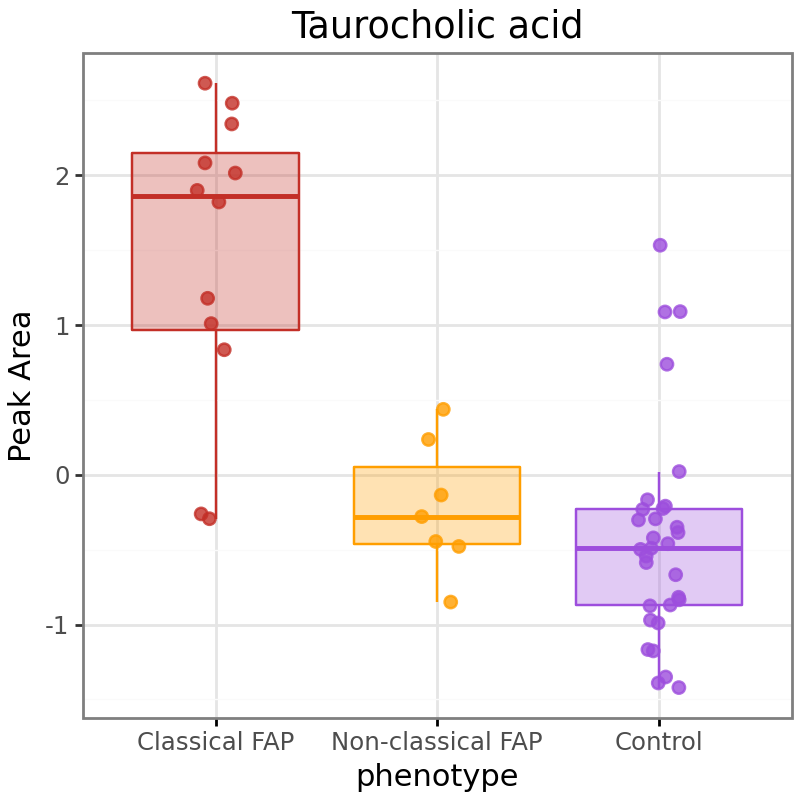

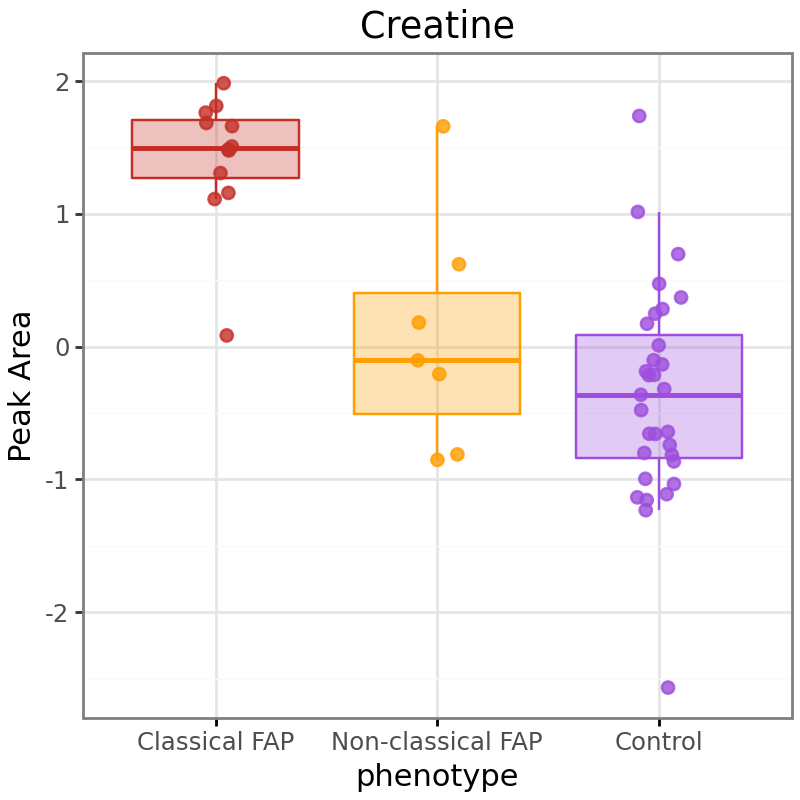

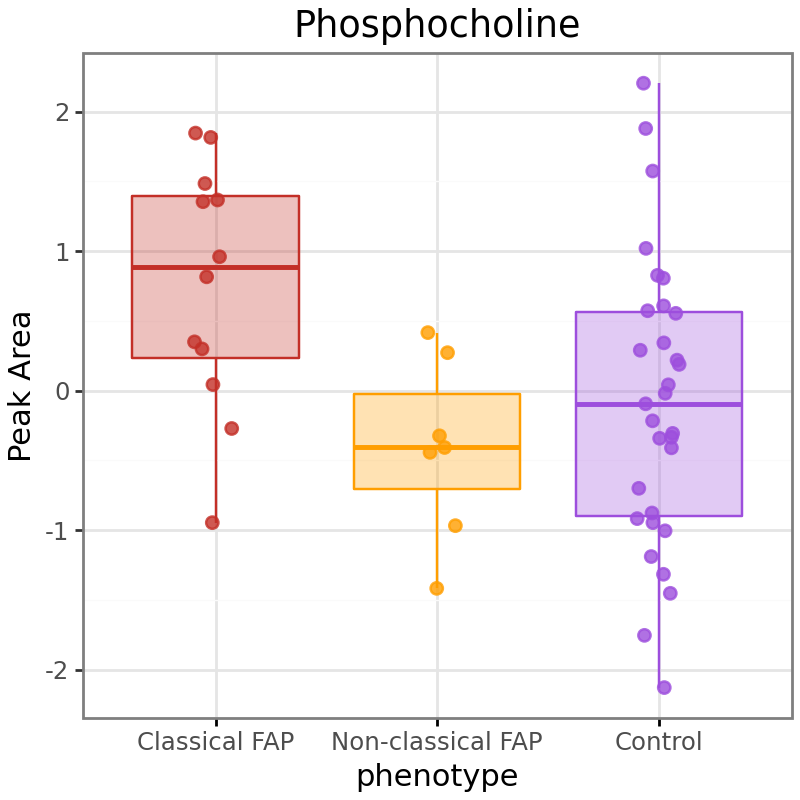

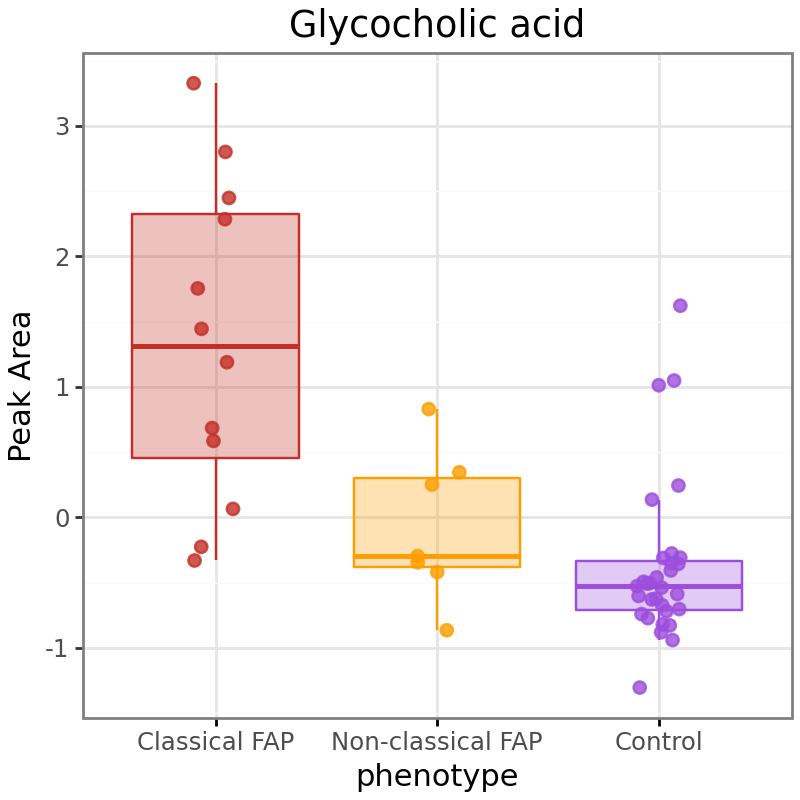

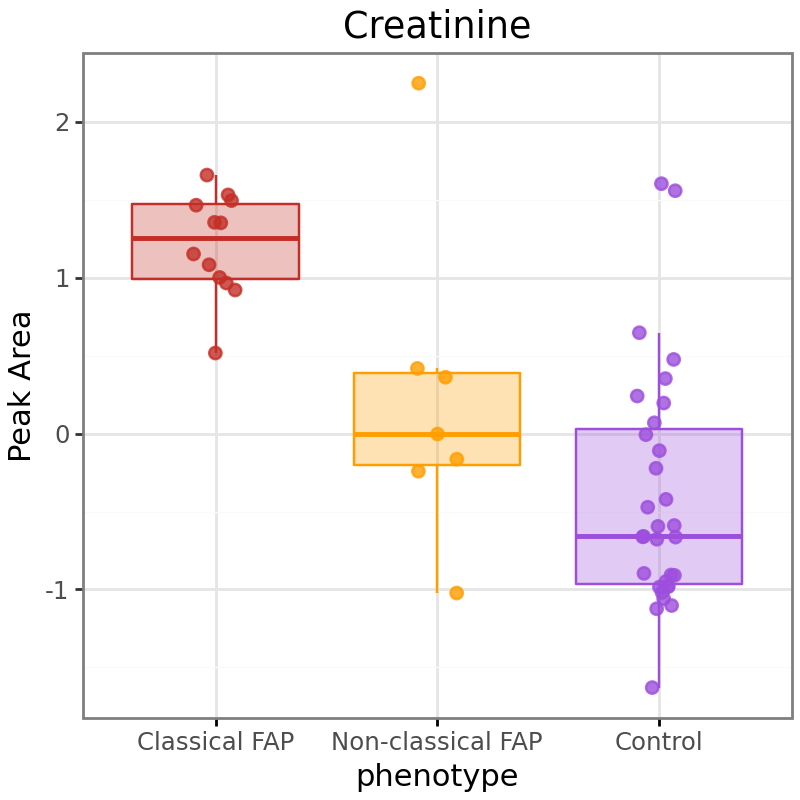

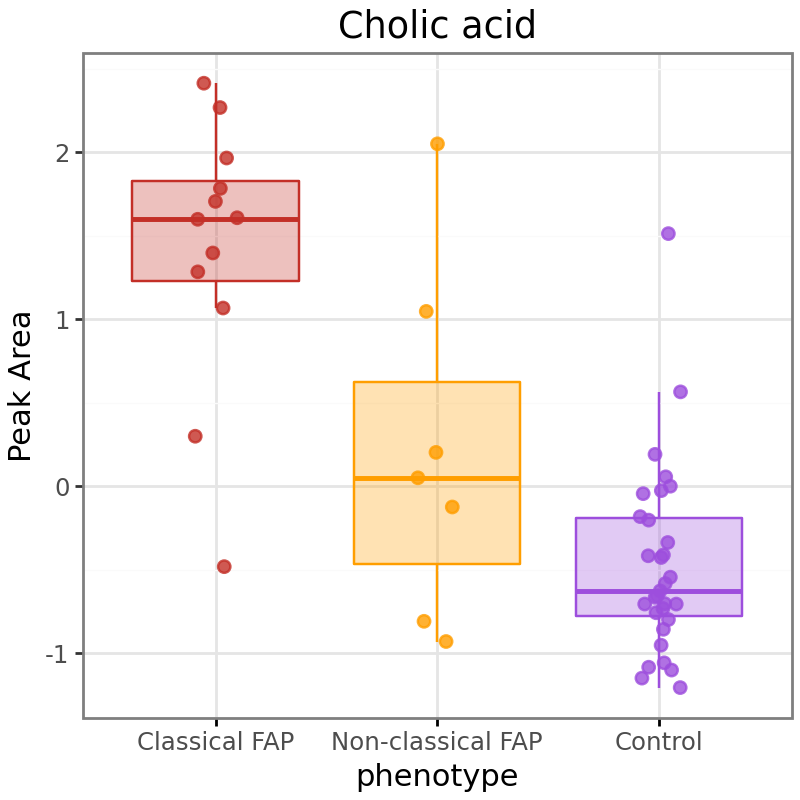

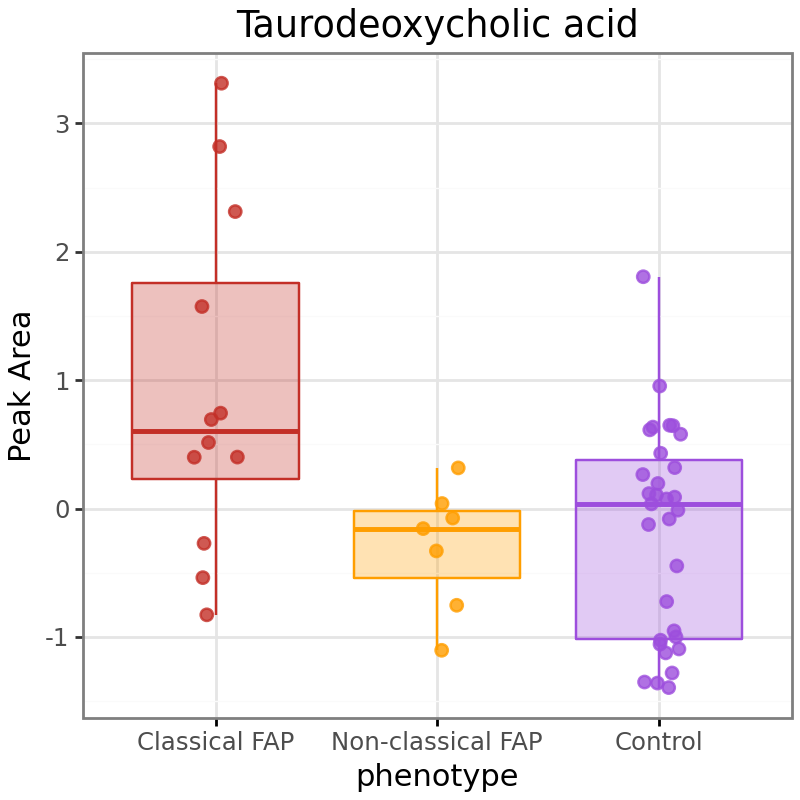

In [95]:
for feature in significant_results[significant_results['color'] == 'Classical FAP']['feature'].tolist():
    ggp = (plot_boxplot_with_scatter(df, "phenotype", feature, "phenotype", title = compund_dict[feature] ) + 
           labs(y = "Peak Area")) + theme(figure_size=(4,4), legend_position="none")
    display(ggp)

### PCA

In [18]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)

X = metabolomics_norm.drop(columns=['case_number'])
principalComponents = pca.fit_transform(X)
pca_df= pd.DataFrame(data = principalComponents, columns = ['PC_1', 'PC_2'], index = metabolomics_norm['case_number']).merge(
                        mdata, left_index=True, right_on='case_number')
explained_variance = pca.explained_variance_ratio_

severity_cats = [*color_mapping][0:4]
pca_df["phenotype"] = pd.Categorical(pca_df["phenotype"], severity_cats)

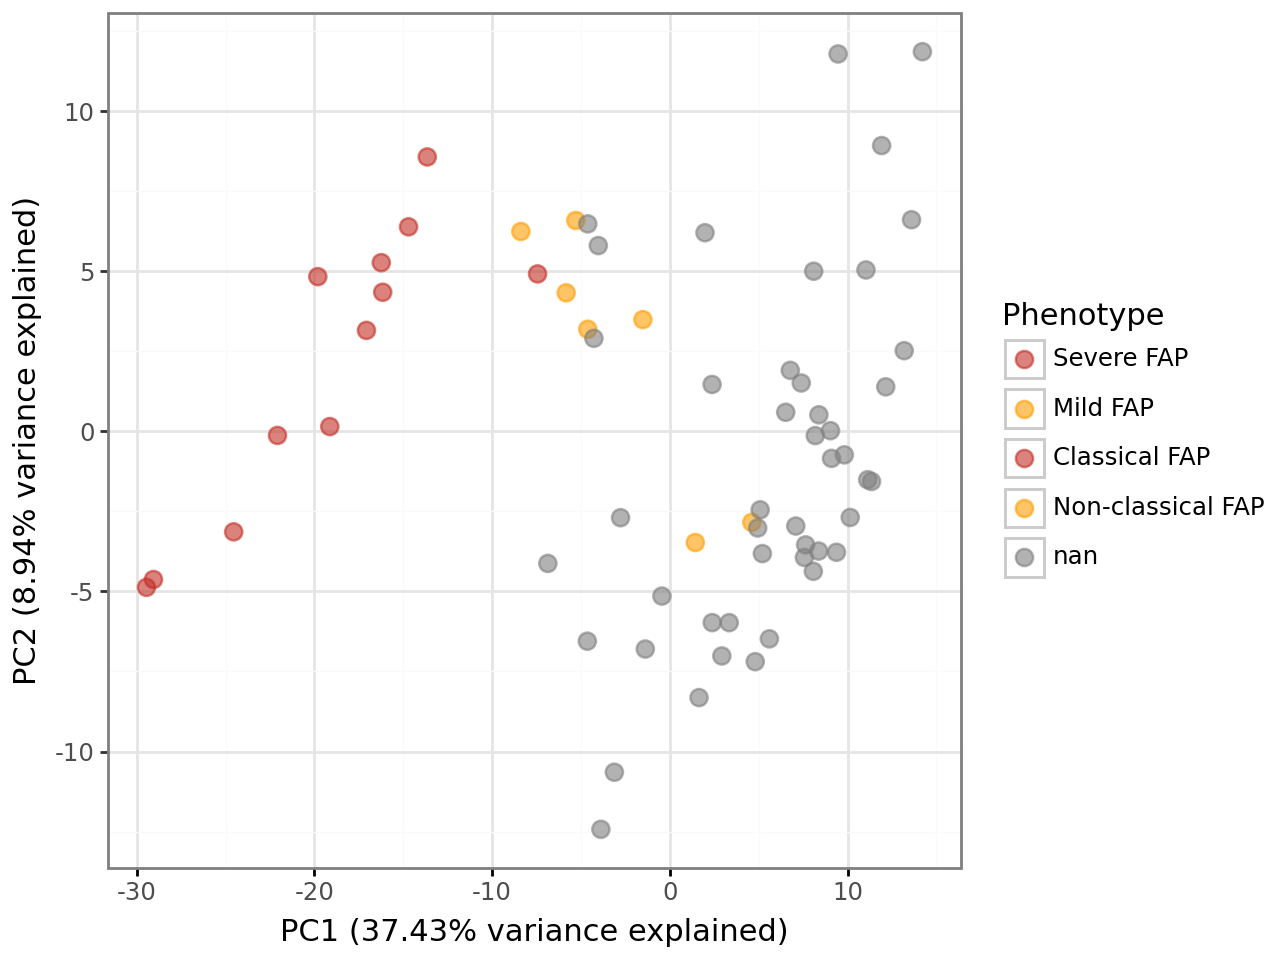

In [19]:
# Create the scatter plot
scatter_plot = (
    ggplot(pca_df, aes(x='PC_1', y='PC_2', color='phenotype')) +
    geom_point(size=3, alpha=0.6) +
    scale_color_manual(values=color_mapping) +
    theme_bw() +
    labs(color='Phenotype',
        x=f'PC1 ({explained_variance[0]*100:.2f}% variance explained)',
        y=f'PC2 ({explained_variance[1]*100:.2f}% variance explained)')
)

scatter_plot

In [20]:
    geom_boxplot(outlier_shape="", alpha=0.3) +  # Align boxes
    geom_jitter(aes(color='phenotype'), size=2, alpha=0.8, position=position_jitterdodge(jitter_width=0.5)) +
    scale_fill_manual(values=color_mapping) +
    scale_color_manual(values=color_mapping) +
    theme_bw() +
    theme(figure_size=(6, 6), legend_position="none") +
    labs( x='Phenotype', y='PC1', fill='Phenotype', color='Phenotype')
)

boxplot_with_scatter

SyntaxError: unmatched ')' (4135819446.py, line 8)

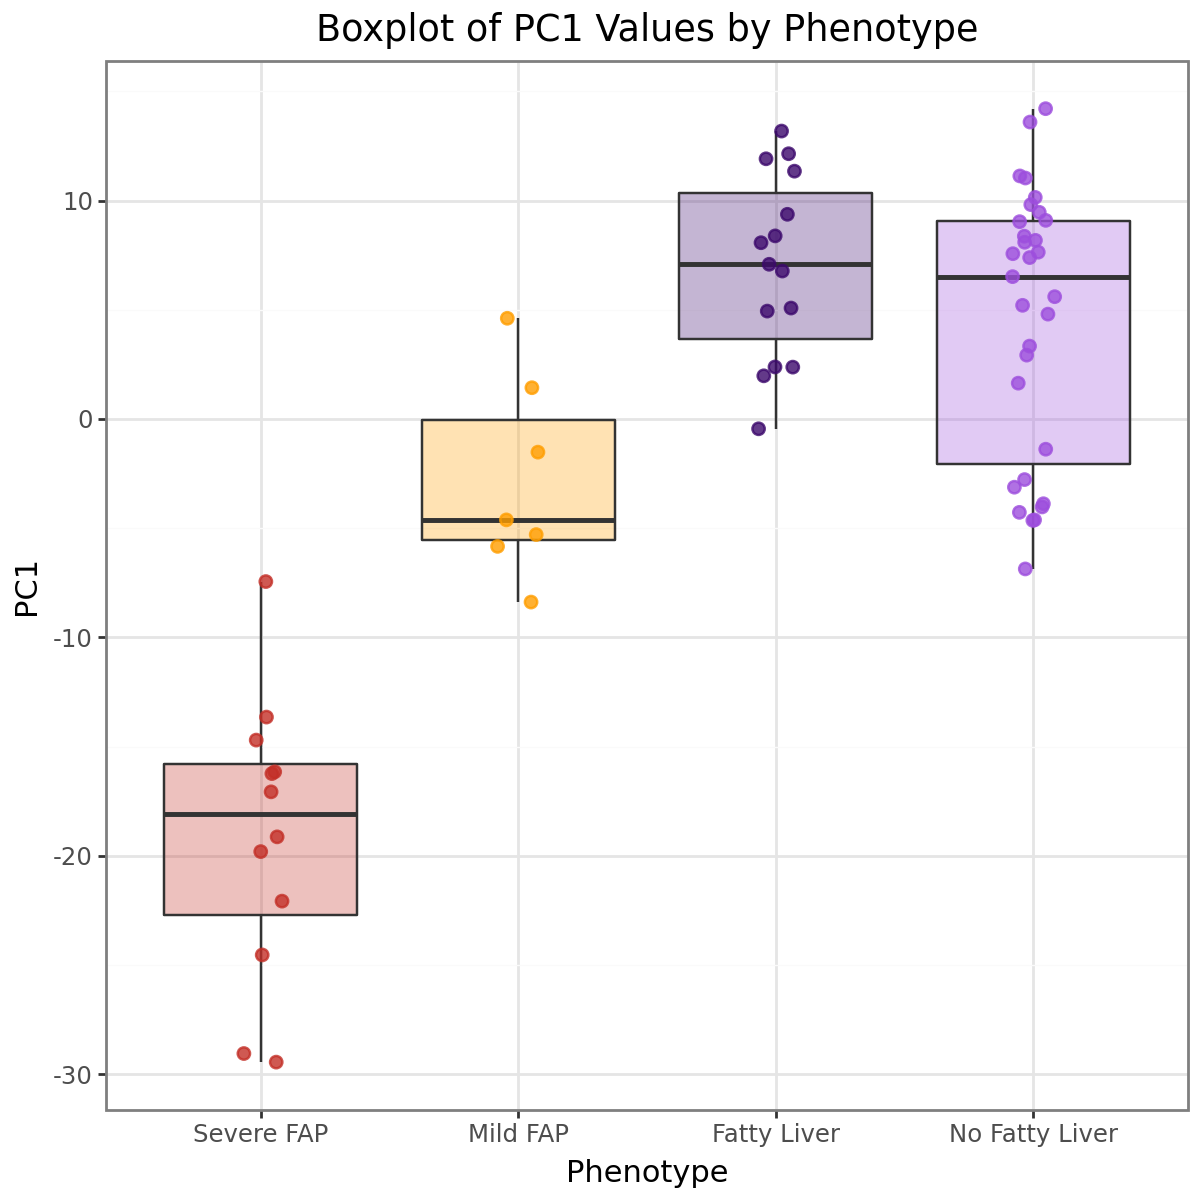

In [ ]:

boxplot_with_scatter = (
    ggplot(pca_df, aes(x='phenotype', y='PC_1', fill='phenotype')) +
    geom_boxplot(outlier_shape="", alpha=0.3) +  # Align boxes
    geom_jitter(aes(color='phenotype'), size=2, alpha=0.8, position=position_jitterdodge(jitter_width=0.5)) +
    scale_fill_manual(values=color_mapping) +
    scale_color_manual(values=color_mapping) +
    theme_bw() +
    theme(figure_size=(6, 6), legend_position="none") +
    labs( x='Phenotype', y='PC1', fill='Phenotype', color='Phenotype')
)

boxplot_with_scatter

In [ ]:
# Sort the feature weights dataframe by pc1_weight# Sort the feature weights dataframe by pc1_weight

,compound_id,pc1_weight,compound_name,compound_class
0,X00171,0.087811,Riboflavin,Vitamin
1,SL00181,0.087313,N-Acetylglutamic acid,Amino acid derivative
2,X00262,0.086127,"γ-Aminobutyric acid/N,N-Dimethylglycine/α-amin...",NaN
3,X00272,0.085761,Isoleucine,Amino acid (essential)
4,X00559,0.085692,Methionine,Amino acid (essential)
...,...,...,...,...
311,X00524,-0.002439,Glycerophosphocholine,Glycerophosphocholines
312,SL00240,-0.001385,Carnosine,Hybrid peptides
313,X02962,-0.001130,"3,4-Dihydroxybenzoic acid",Benzoic acids and derivatives
314,X01032,-0.001118,"Salicylic acid/2,4-Dihydroxybenzaldehyde/3-Hyd...",NaN


In [ ]:

pc1_weights = pca.components_[0]
feature_weights_df = pd.DataFrame({'compound_id': metabolomics_norm.columns[1:], 'pc1_weight': pc1_weights})
feature_weights_df = feature_weights_df.reindex(feature_weights_df['pc1_weight'].abs().sort_values(ascending=False).index).merge(compound_names, on='compound_id')

print(feature_weights_df)

In [ ]:
feature_weights_df[feature_weights_df.compound_name == '3-Methylglutaric acid/2-Methylglutaric acid']

,compound_id,pc1_weight,compound_name,compound_class
62,X06814,0.075439,3-Methylglutaric acid/2-Methylglutaric acid,Fatty acids and conjugates/ Fatty acids and co...
63,X06814,0.075439,3-Methylglutaric acid/2-Methylglutaric acid,Fatty acids and conjugates/ Fatty acids and co...


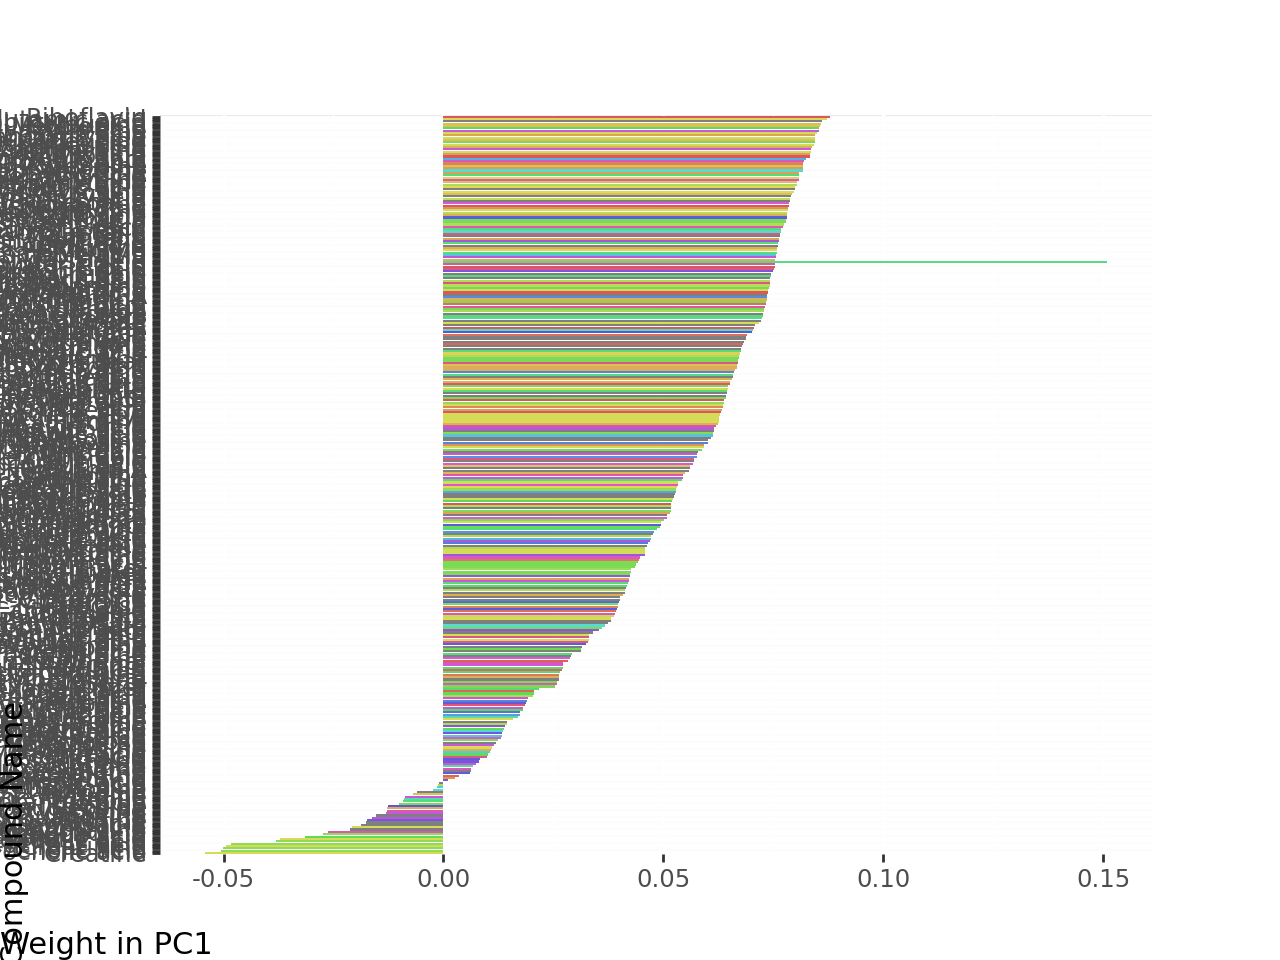

In [ ]:
feature_weights_df
bar_plot = (
    ggplot(feature_weights_df, aes(x='reorder(compound_name, pc1_weight)', y='pc1_weight', fill='compound_class')) +
    geom_col() + coord_flip() + theme(legend_position= "none") +
    labs(title=f'Top {n} Most Important Features by Weight in PC1',
         x='Compound Name',
         y='Weight in PC1',
         fill='Compound Category')
)

bar_plot

In [ ]:

pc1_weights = pca.components_[0]
feature_weights_df = pd.DataFrame({'compound_id': metabolomics_norm.columns[1:], 'pc1_weight': pc1_weights})
feature_weights_df = feature_weights_df.reindex(feature_weights_df['pc1_weight'].abs().sort_values(ascending=False).index).merge(compound_names, on='compound_id')

print(feature_weights_df)

    compound_id  pc1_weight  \
0        X00171    0.087811   
1       SL00181    0.087313   
2        X00262    0.086127   
3        X00272    0.085761   
4        X00559    0.085692   
..          ...         ...   
311      X00524   -0.002439   
312     SL00240   -0.001385   
313      X02962   -0.001130   
314      X01032   -0.001118   
315      X00624    0.001009   

                                         compound_name  \
0                                           Riboflavin   
1                                N-Acetylglutamic acid   
2    γ-Aminobutyric acid/N,N-Dimethylglycine/α-amin...   
3                                           Isoleucine   
4                                           Methionine   
..                                                 ...   
311                              Glycerophosphocholine   
312                                          Carnosine   
313                          3,4-Dihydroxybenzoic acid   
314  Salicylic acid/2,4-Dihydroxybenzaldehyde/3

In [ ]:
principalDf.head()

,principal component 1,principal component 2
0,-22.080242,-0.124500
1,-16.159502,4.348917
2,-4.622213,3.192223
3,-29.452827,-4.870872
4,-5.295178,6.591338


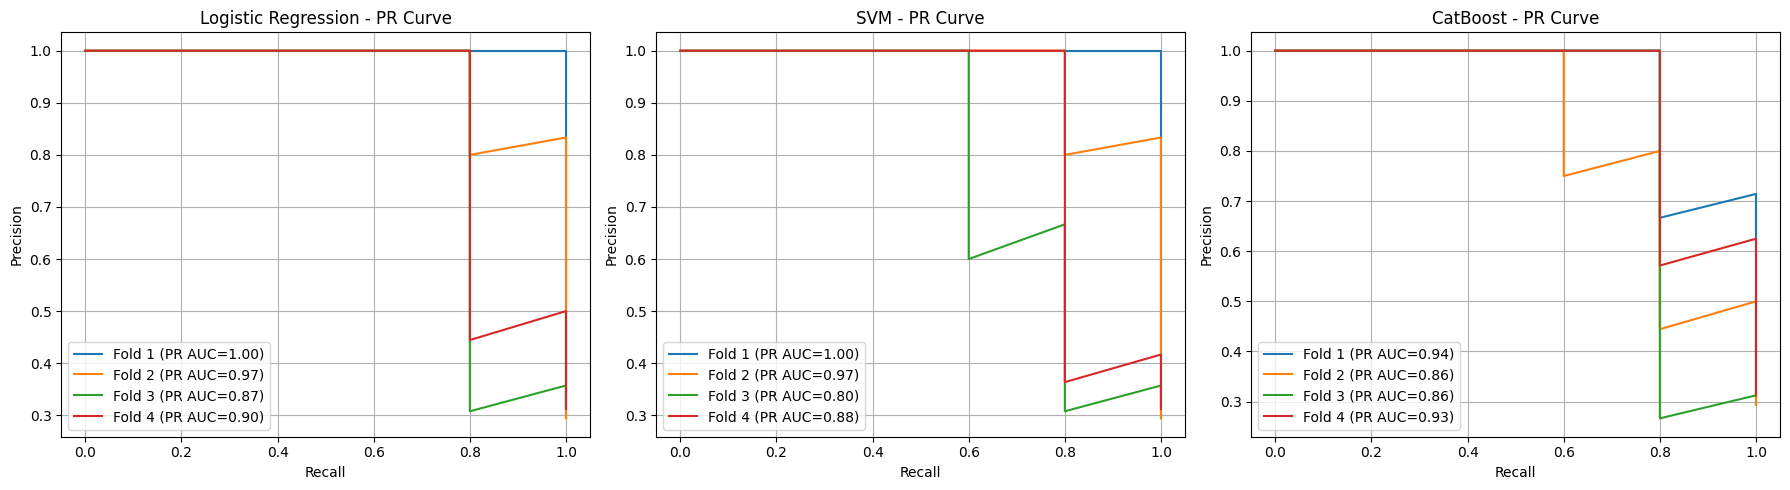

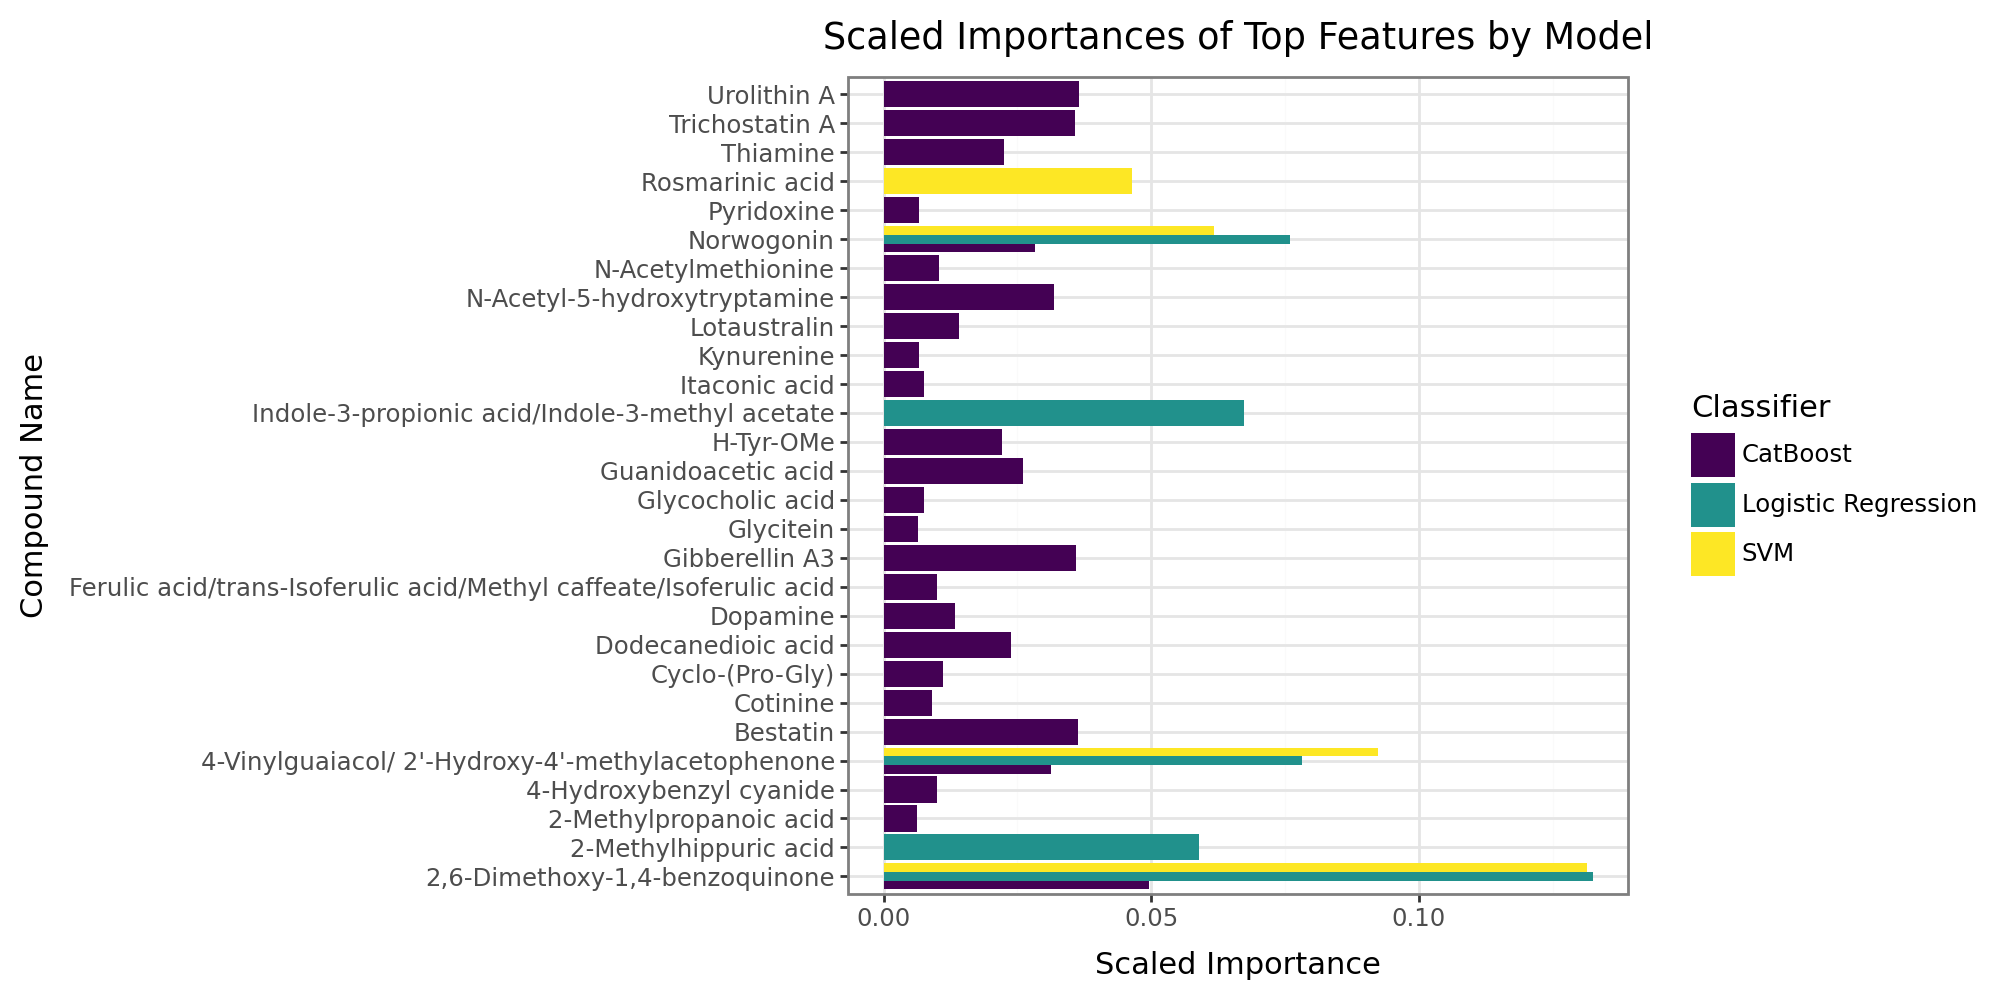

In [ ]:
# Create the bar plot
bar_plot = (
    ggplot(top_features_df, aes(x='compound_name', y='scaled_importance', fill='model')) +
    geom_col(position='dodge') +
    scale_fill_cmap_d() +
    theme_bw() +
    coord_flip() +
    labs(title='Scaled Importances of Top Features by Model', x='Compound Name', y='Scaled Importance', fill='Classifier')
)

bar_plot = bar_plot + theme(figure_size=(10,5))
bar_plot

In [ ]:
df['fap_status'] = df['is_fap'].apply(lambda x: 'FAP' if x == 1 else 'No FAP')

C:\Users\alisa\AppData\Local\Temp\ipykernel_25324\3326907307.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


In [ ]:
mdata_columns = ['is_fap', 'sample', 'indication']
duplicate_compounds = top_features_df["compound_name"].value_counts()
duplicate_compounds = duplicate_compounds[duplicate_compounds > 1].index.tolist()
duplicate_compound_ids = compound_names[compound_names['compound_name'].isin(duplicate_compounds)]['compound_id'].tolist()

df_selected = df[duplicate_compound_ids + mdata_columns]
df_selected = df_selected.melt(id_vars=['is_fap', 'sample', 'indication'], var_name='compound_id', value_name='value')
df_selected = df_selected.merge(compound_names, on='compound_id')
df_selected["is_fap"] = df_selected["is_fap"].apply(lambda x: 'FAP' if x == 1 else 'No FAP')

In [ ]:
df_selected.head()

,is_fap,sample,indication,compound_id,value,compound_name,compound_class
0,FAP,36161549,FAP,SL00139,-1.989978,"2,6-Dimethoxy-1,4-benzoquinone",Carbonyl compounds
1,FAP,35727911,FAP,SL00139,-1.422078,"2,6-Dimethoxy-1,4-benzoquinone",Carbonyl compounds
2,FAP,35956773,FAP,SL00139,-1.497862,"2,6-Dimethoxy-1,4-benzoquinone",Carbonyl compounds
3,FAP,36532014,FAP,SL00139,-2.837920,"2,6-Dimethoxy-1,4-benzoquinone",Carbonyl compounds
4,FAP,36531969,FAP,SL00139,-0.489710,"2,6-Dimethoxy-1,4-benzoquinone",Carbonyl compounds


In [ ]:
p_values = []
for cat in df_selected["compound_name"].unique():
    print(cat)
    group_x = df_selected[(df_selected["compound_name"] == cat) & (df_selected["is_fap"] == "FAP")]["value"]
    group_y = df_selected[(df_selected["compound_name"] == cat) & (df_selected["is_fap"] == "No FAP")]["value"]

    stat, p = mannwhitneyu(group_x, group_y, alternative="two-sided")
    p_values.append({"compund_name": cat, "p_value": p})

# Convert to DataFrame
pval_df = pd.DataFrame(p_values)
pval_df["fdr"] = multipletests(pval_df["p_value"], method="fdr_bh")[1]
pval_df

2,6-Dimethoxy-1,4-benzoquinone
4-Vinylguaiacol/ 2'-Hydroxy-4'-methylacetophenone
Norwogonin


,compund_name,p_value,fdr
0,"2,6-Dimethoxy-1,4-benzoquinone",3.705255e-08,5.557882e-08
1,4-Vinylguaiacol/ 2'-Hydroxy-4'-methylacetophenone,3.705255e-08,5.557882e-08
2,Norwogonin,9.087680e-05,9.087680e-05


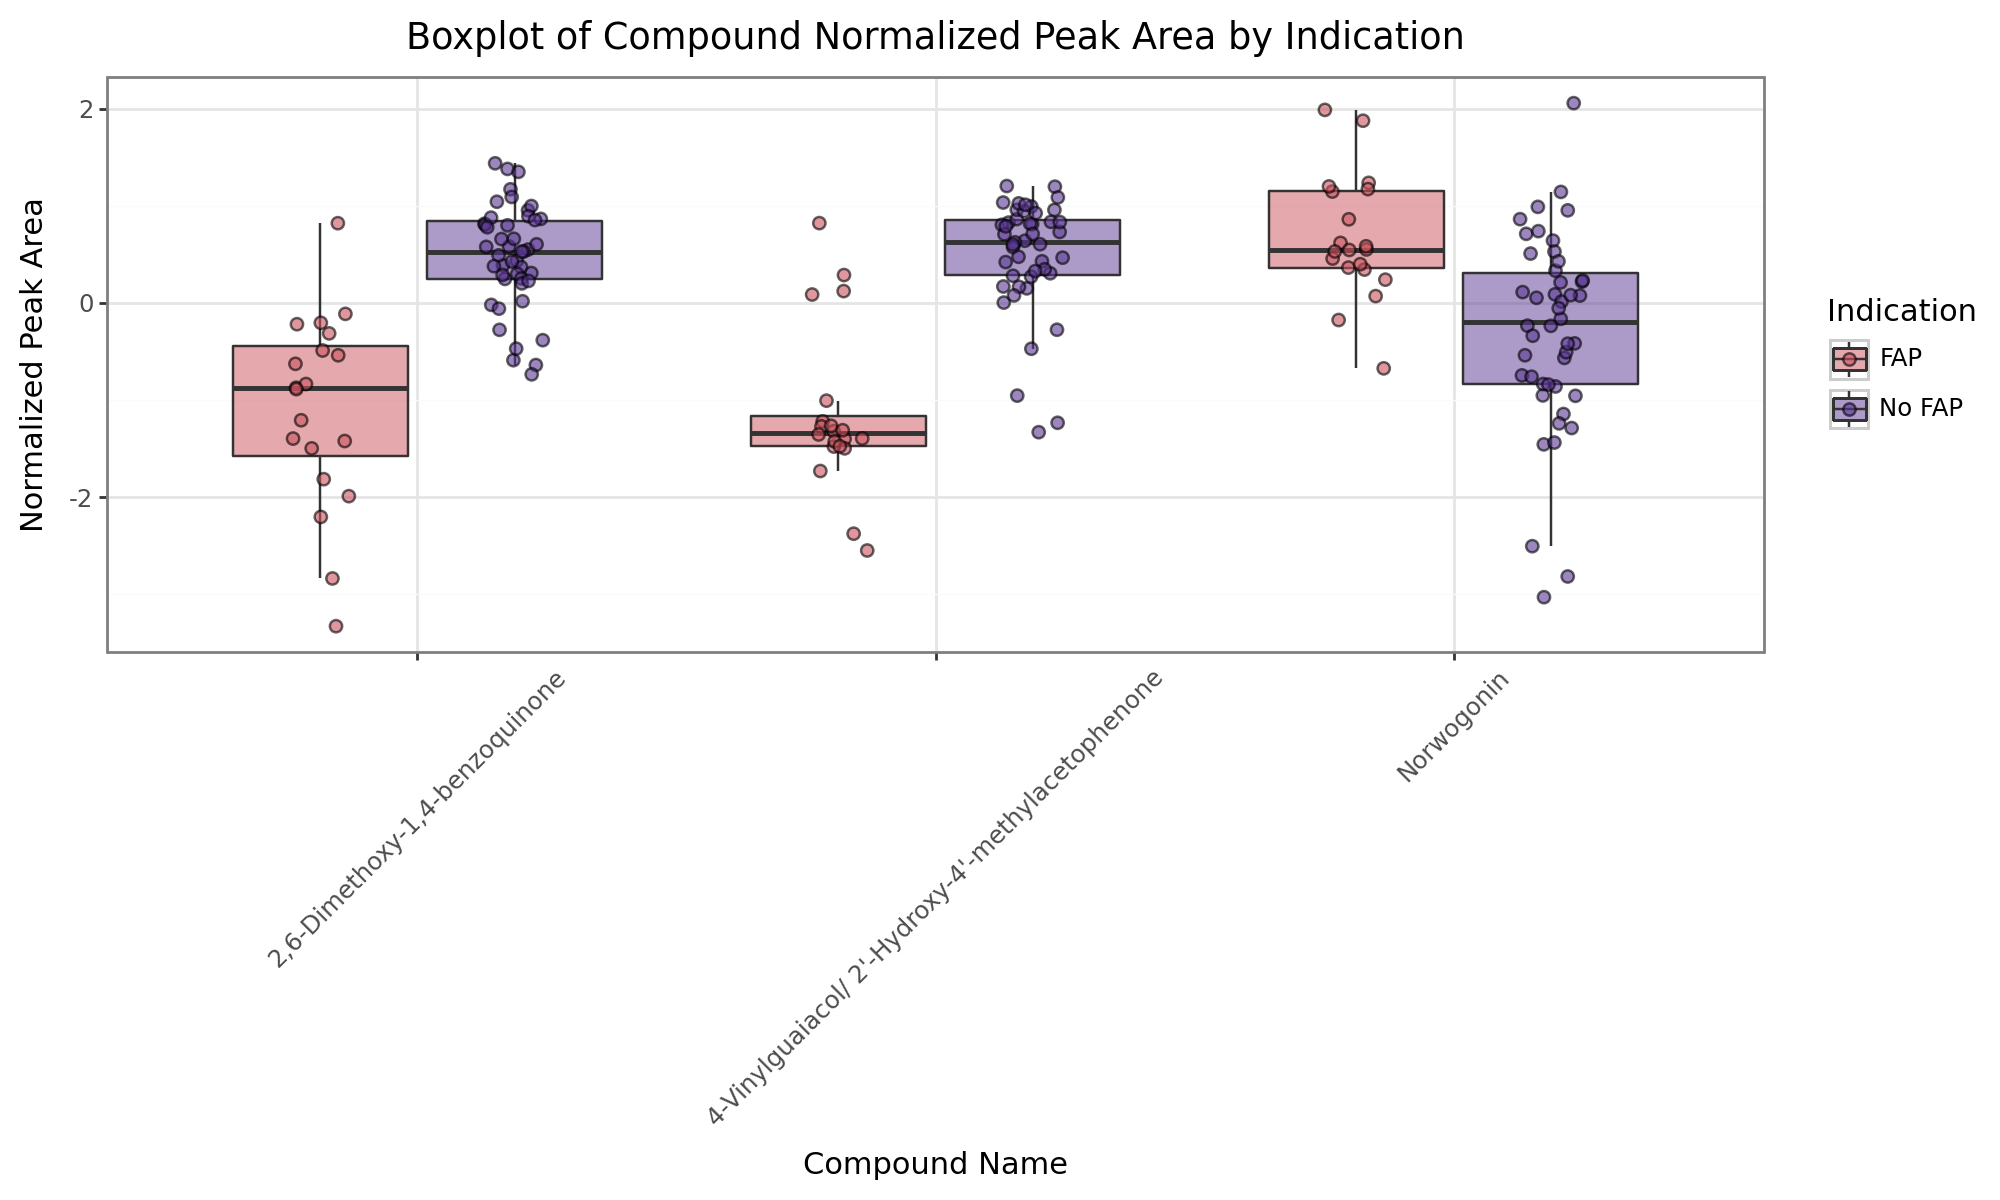

In [ ]:
# Create the boxplot

(
    ggplot(df_selected, aes(x='compound_name', y='value', fill='factor(is_fap)')) +
    geom_boxplot(outlier_shape="", alpha = 0.5) +  # Align boxes
    geom_jitter(color = "black",size=2, alpha=0.6, position = position_jitterdodge(jitter_width = .25)) +
    theme_bw() + theme(figure_size= (10,6), axis_text_x= element_text(rotation=45)) + 
    labs(title='Boxplot of Compound Normalized Peak Area by Indication', x='Compound Name', y='Normalized Peak Area', fill='Indication') + 
    scale_fill_manual(values=color_mapping)
)